# ENGE707 Assessment 3 - Facial Feature Classification Challenge
**Kaggle username:** `<ADD YOUR KAGGLE USERNAME>`  |  **Student ID:** `<ADD>`

Eight-class classification (CatEye, CatFace, CatMouth, CatNose, DogEye, DogFace, DogMouth, DogNose) with a
pretrained **ResNet-18** fine-tuned end to end on CPU.

**How to reproduce**
1. `pip install torch torchvision timm scikit-learn pandas matplotlib seaborn`
2. Unzip the Kaggle data so `DATA_DIR` contains `train/train`, `test/test`, `train_labels.csv`, `sample_submission.csv`.
3. `export DATA_DIR=... CACHE_DIR=...` then run `python src/cache_data.py`, `python src/eda.py`,
   `bash run_experiments.sh`, `python src/evaluate_predict.py --model resnet18 --size 64 --submit`.
4. This notebook displays the saved results (set `RUN_TRAINING = True` to retrain from inside the notebook).

In [1]:
import sys, os, json, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, 'src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from config import *
RUN_TRAINING = False   # ~45 min per model on a 16-core CPU
if RUN_TRAINING:
    from pipeline import train
    train('resnet18', 64, 5, tag='resnet18_64')
    train('smallcnn', 64, 5, pretrained=False, lr=3e-3, tag='smallcnn_64')
print('device: CPU', '| image cache size:', IMG_SIZE)

device: CPU | image cache size: 96


## 1. Dataset exploration (Task 1)

n_train                    63660.000000
n_test                     29443.000000
train_dup_files               15.000000
test_dup_files                62.000000
test_in_train_dup              0.000000
conflicting_label_dups         0.000000
train_min_side                 4.000000
test_min_side                  8.000000
train_max_side              2219.000000
test_max_side               1978.000000
train_nonsquare_frac           0.344801
test_nonsquare_frac            0.671501
train_tiny_lt24             1290.000000
test_tiny_lt24               648.000000
blur_p5_laplace_var           16.346010
blur_median_laplace_var      388.229065


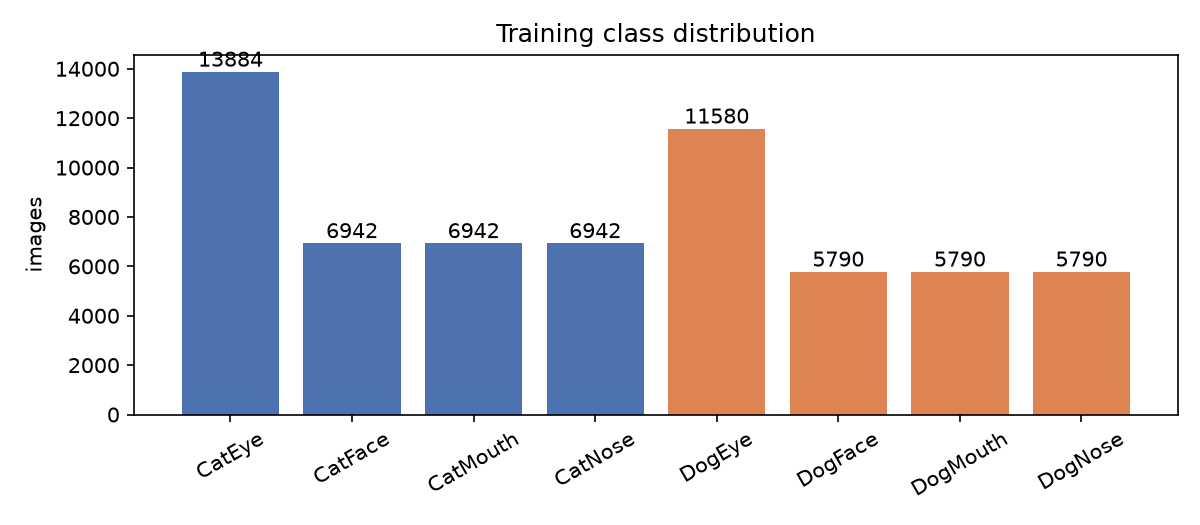

In [2]:
stats = json.load(open(OUT_DIR/'eda_stats.json')); print(pd.Series(stats).to_string())
display(Image(str(OUT_DIR/'class_distribution.png')))

The training set has 63,660 labelled images and the test set 29,443 unlabelled images. The two Eye classes contain
twice as many images as the other classes (a left and a right eye per animal), so the data are imbalanced 2:1 for
Eye vs non-Eye. Per species, the 4 classes are CatEye 21.8 %, others 10.9 % each.

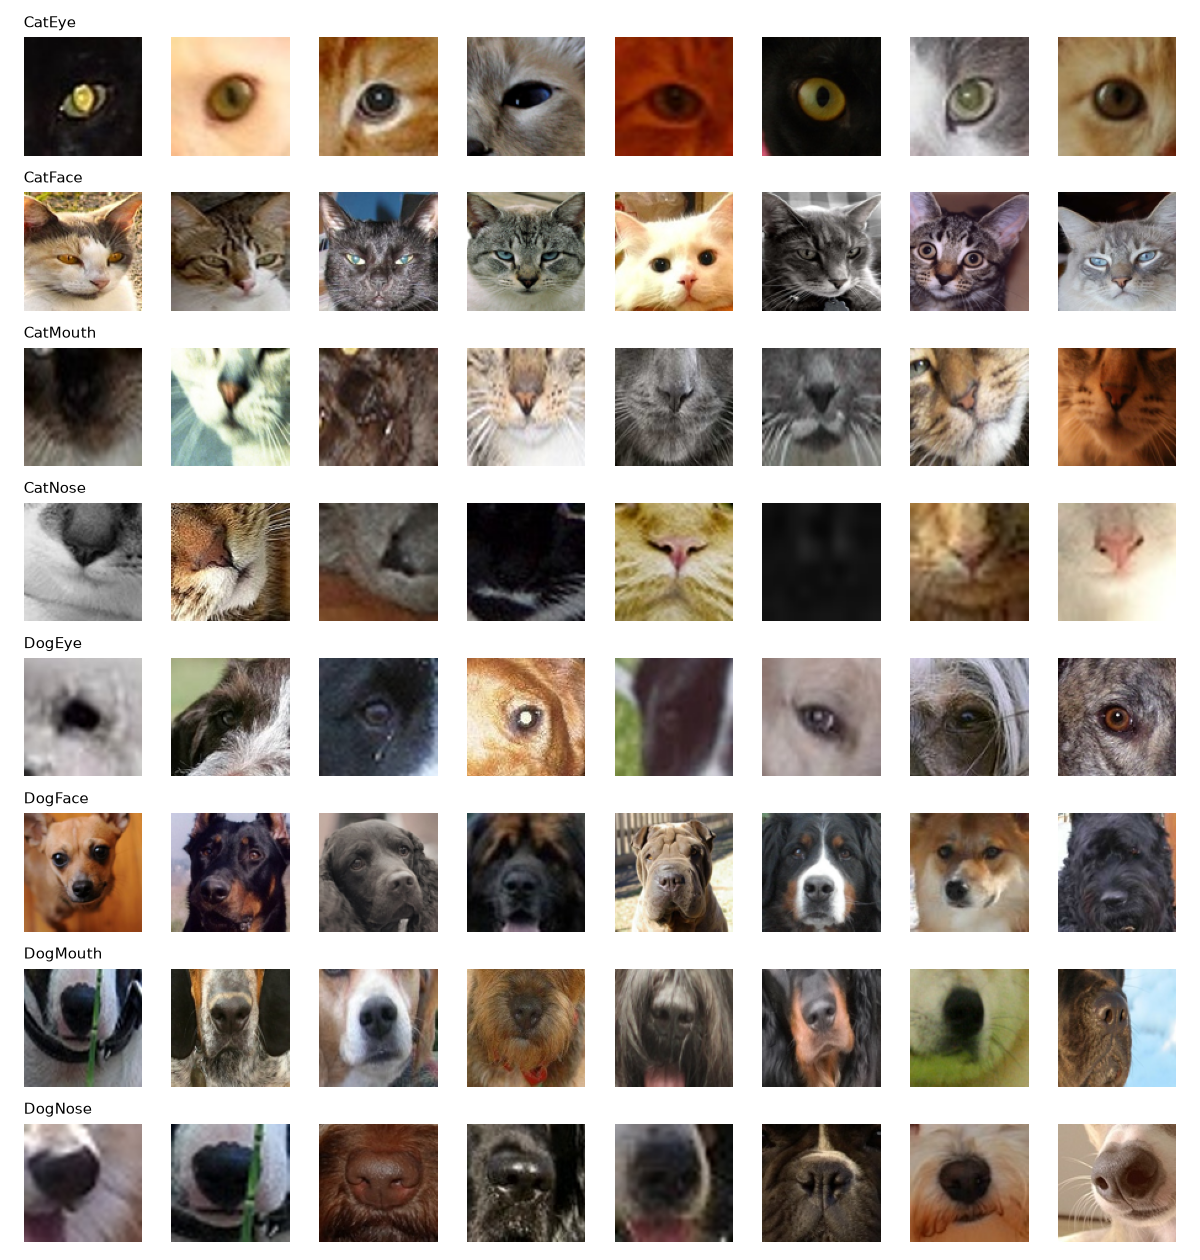

In [3]:
display(Image(str(OUT_DIR/'samples_per_class.png')))

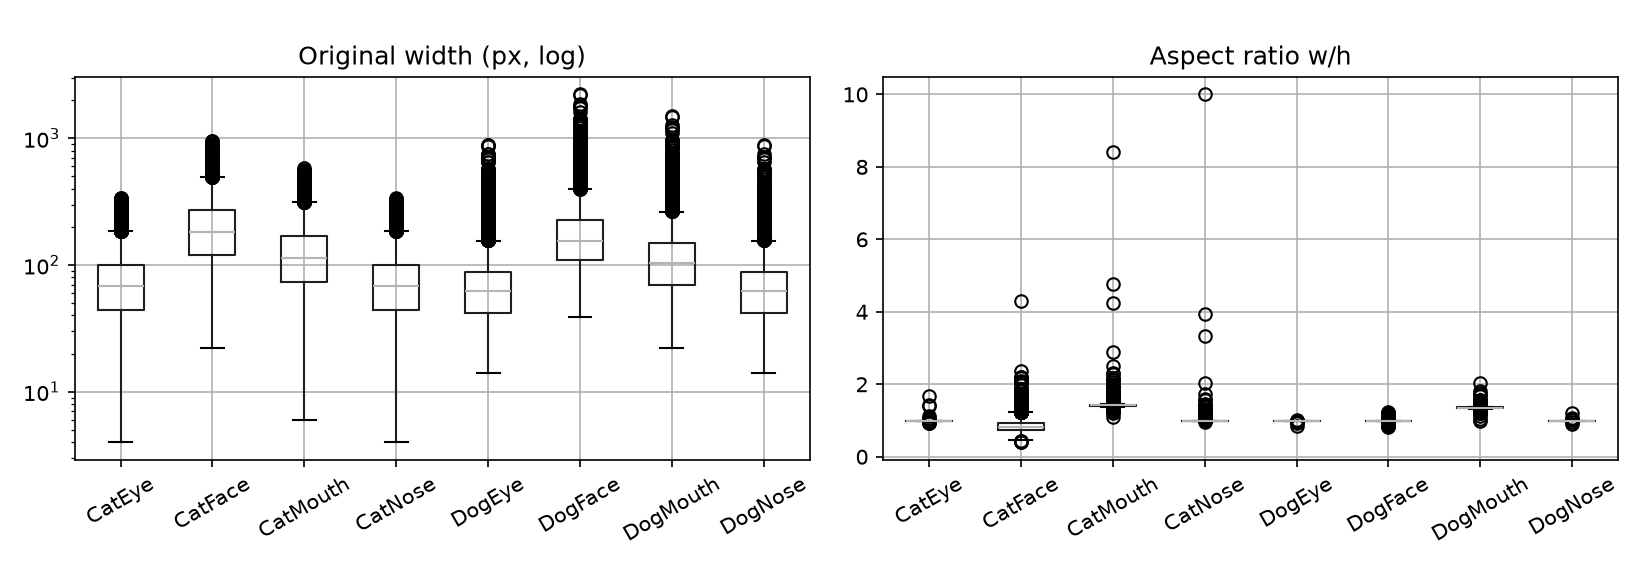

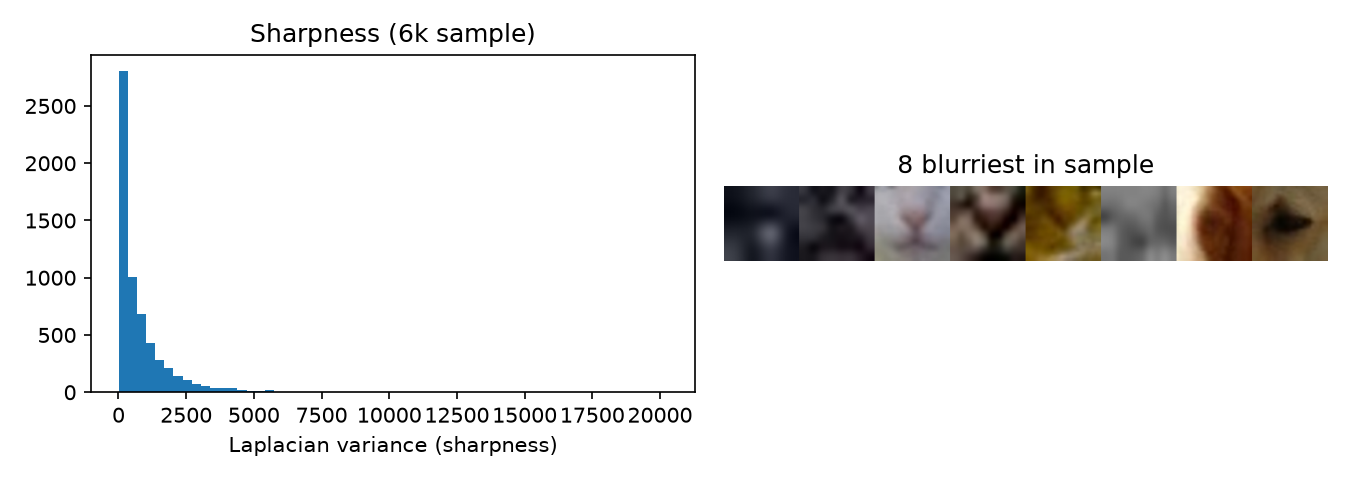

              w                h          
           mean min   max   mean min   max
cls                                       
CatEye     78.9   4   340   78.9   4   340
CatFace   213.8  22   955  251.0  28  1024
CatMouth  133.2   6   578   93.4   4   394
CatNose    78.9   4   340   78.7   4   340
DogEye     75.3  14   886   75.3  14   886
DogFace   190.3  39  2219  190.1  40  2219
DogMouth  127.1  22  1506   93.8  17  1107
DogNose    75.3  14   886   75.3  14   886


In [4]:
display(Image(str(OUT_DIR/'size_by_class.png'))); display(Image(str(OUT_DIR/'blur.png'))); print(pd.read_csv(OUT_DIR/'size_stats.csv', header=[0,1], index_col=0))

**Data-quality findings.** Source crops range from 4 to 2219 px and are often non-square, with size strongly tied to
class (faces are large, mouths are wide). 15 exact duplicate files exist inside train (none with conflicting labels and
none shared with test); these are grouped by MD5 so they cannot straddle the train/validation split. Roughly 2 % of
images are under 24 px and a tail of blurry/dark crops exists. Mouth and Nose crops of the same species overlap visually
(unclear class boundary). Use: 90 % of labelled data to train, 10 % stratified hold-out to validate, test set only for
the Kaggle submission.

## 2. Preprocessing and pipeline (Task 2)

In [5]:
import inspect, pipeline
print(inspect.getsource(pipeline.make_split)); print(inspect.getsource(pipeline.augment))
print(open('src/cache_data.py').read()[:1500])

def make_split(y, md5, val_frac=0.1):
    """Stratified split; identical files (same md5) are kept on the same side (no leakage)."""
    skf = StratifiedGroupKFold(n_splits=int(round(1 / val_frac)), shuffle=True, random_state=SEED)
    tr, va = next(skf.split(np.zeros(len(y)), y, groups=md5))
    return tr, va

def augment(x, size):
    """Batch augmentation on [0,1] tensors: h-flip, random scale/translate/rotate, brightness/contrast."""
    B = x.shape[0]
    flip = (torch.rand(B) < 0.5).float() * 2 - 1
    scale = torch.empty(B).uniform_(0.85, 1.15)
    ang = torch.empty(B).uniform_(-15, 15) * np.pi / 180
    tx, ty = torch.empty(B).uniform_(-0.1, 0.1), torch.empty(B).uniform_(-0.1, 0.1)
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos * flip, -sin, tx], 1),
                         torch.stack([sin * flip, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinea

All images (train and test) go through the identical deterministic path: decode -> RGB -> bicubic resize to 96x96
(cached as uint8) -> area-downscale to 64x64 -> /255 -> ImageNet mean/std normalisation. Labels are encoded to
integers 0-7. Augmentation (training only, applied on-the-fly to each batch): horizontal flip, rotation +/-15 deg,
scale 0.85-1.15, translation +/-10 %, brightness/contrast jitter. No vertical flips (faces are never upside down).
Because the split is performed before any statistics are fitted and the test data are only ever passed through the same
fixed transform, there is no leakage.

## 3. Model (Task 3)

In [6]:
import torch, timm
from pipeline import build_model
m = build_model('resnet18', pretrained=False); s = build_model('smallcnn')
print('ResNet-18 params: %.2fM | SmallCNN params: %.2fM' % (sum(p.numel() for p in m.parameters())/1e6, sum(p.numel() for p in s.parameters())/1e6))
print(m.fc)

ResNet-18 params: 11.18M | SmallCNN params: 1.18M
Linear(in_features=512, out_features=8, bias=True)


**Chosen model: ResNet-18 (timm `resnet18.a1_in1k` ImageNet weights)**, input 3x64x64, global-average-pool, dropout 0.2,
linear layer with 8 outputs, softmax inside the cross-entropy loss. Loss: cross-entropy with label smoothing 0.1.
Optimiser: AdamW (weight decay 0.05), OneCycle schedule (peak LR 2e-3, 20 % warm-up, cosine decay), batch size 128,
5 epochs. A from-scratch 4-block CNN (`SmallCNN`) is the baseline.

## 4. Training behaviour (Task 4)

resnet18_64
 epoch  train_loss  train_acc  val_loss  val_acc
     1      0.9313     0.7976    0.2094   0.9601
     2      0.5425     0.9695    0.1402   0.9799
     3      0.5156     0.9812    0.1207   0.9879
     4      0.4991     0.9875    0.1126   0.9920
     5      0.4889     0.9918    0.1095   0.9925
smallcnn_64
 epoch  train_loss  train_acc  val_loss  val_acc
     1      1.0400     0.7535    0.2693   0.9417
     2      0.6444     0.9479    0.2031   0.9694
     3      0.5861     0.9679    0.1455   0.9788
     4      0.5521     0.9786    0.1314   0.9860
     5      0.5308     0.9864    0.1185   0.9873


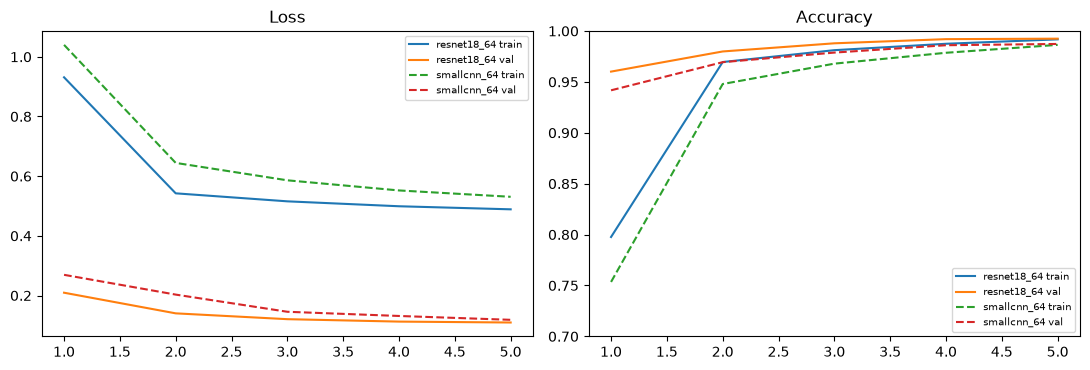

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for tag, ls in [('resnet18_64','-'), ('smallcnn_64','--')]:
    f = OUT_DIR/f'history_{tag}.json'
    if not f.exists(): continue
    h = pd.DataFrame(json.load(open(f)))
    ax[0].plot(h.epoch, h.train_loss, ls, label=f'{tag} train'); ax[0].plot(h.epoch, h.val_loss, ls, label=f'{tag} val')
    ax[1].plot(h.epoch, h.train_acc, ls, label=f'{tag} train'); ax[1].plot(h.epoch, h.val_acc, ls, label=f'{tag} val')
    print(tag); print(h[['epoch','train_loss','train_acc','val_loss','val_acc']].round(4).to_string(index=False))
ax[0].set_title('Loss'); ax[1].set_title('Accuracy'); ax[1].set_ylim(0.7, 1); [a.legend(fontsize=7) or a.set_xlabel('epoch') for a in ax]
plt.tight_layout(); plt.savefig(OUT_DIR/'learning_curves.png', dpi=150); plt.show()

Training accuracy is *lower* than validation accuracy in early epochs because training batches are augmented and use
label smoothing, while validation images are clean. The gap closes by epoch 5 and neither model shows a rising
validation loss, so there is no sign of over-fitting; the from-scratch baseline is the one that is limited by
under-fitting/capacity at this budget.

## 5. Evaluation and Kaggle submission (Task 5)

resnet18_64 {'plain': {'acc': 0.9924611276896498, 'loss': 0.10952727496623993}, 'tta': {'acc': 0.9937176064080414, 'loss': 0.10881146043539047}}
smallcnn_64 {'plain': {'acc': 0.987278152976284, 'loss': 0.1185242310166359}, 'tta': {'acc': 0.9891628710538716, 'loss': 0.11730699986219406}}
              precision  recall  f1-score    support
CatEye           0.9964  0.9964    0.9964  1389.0000
CatFace          0.9986  1.0000    0.9993   695.0000
CatMouth         0.9746  0.9942    0.9843   694.0000
CatNose          0.9883  0.9697    0.9789   694.0000
DogEye           0.9957  0.9965    0.9961  1158.0000
DogFace          0.9983  0.9983    0.9983   579.0000
DogMouth         0.9983  0.9965    0.9974   579.0000
DogNose          0.9983  0.9948    0.9965   579.0000
accuracy         0.9937  0.9937    0.9937     0.9937
macro avg        0.9935  0.9933    0.9934  6367.0000
weighted avg     0.9937  0.9937    0.9937  6367.0000


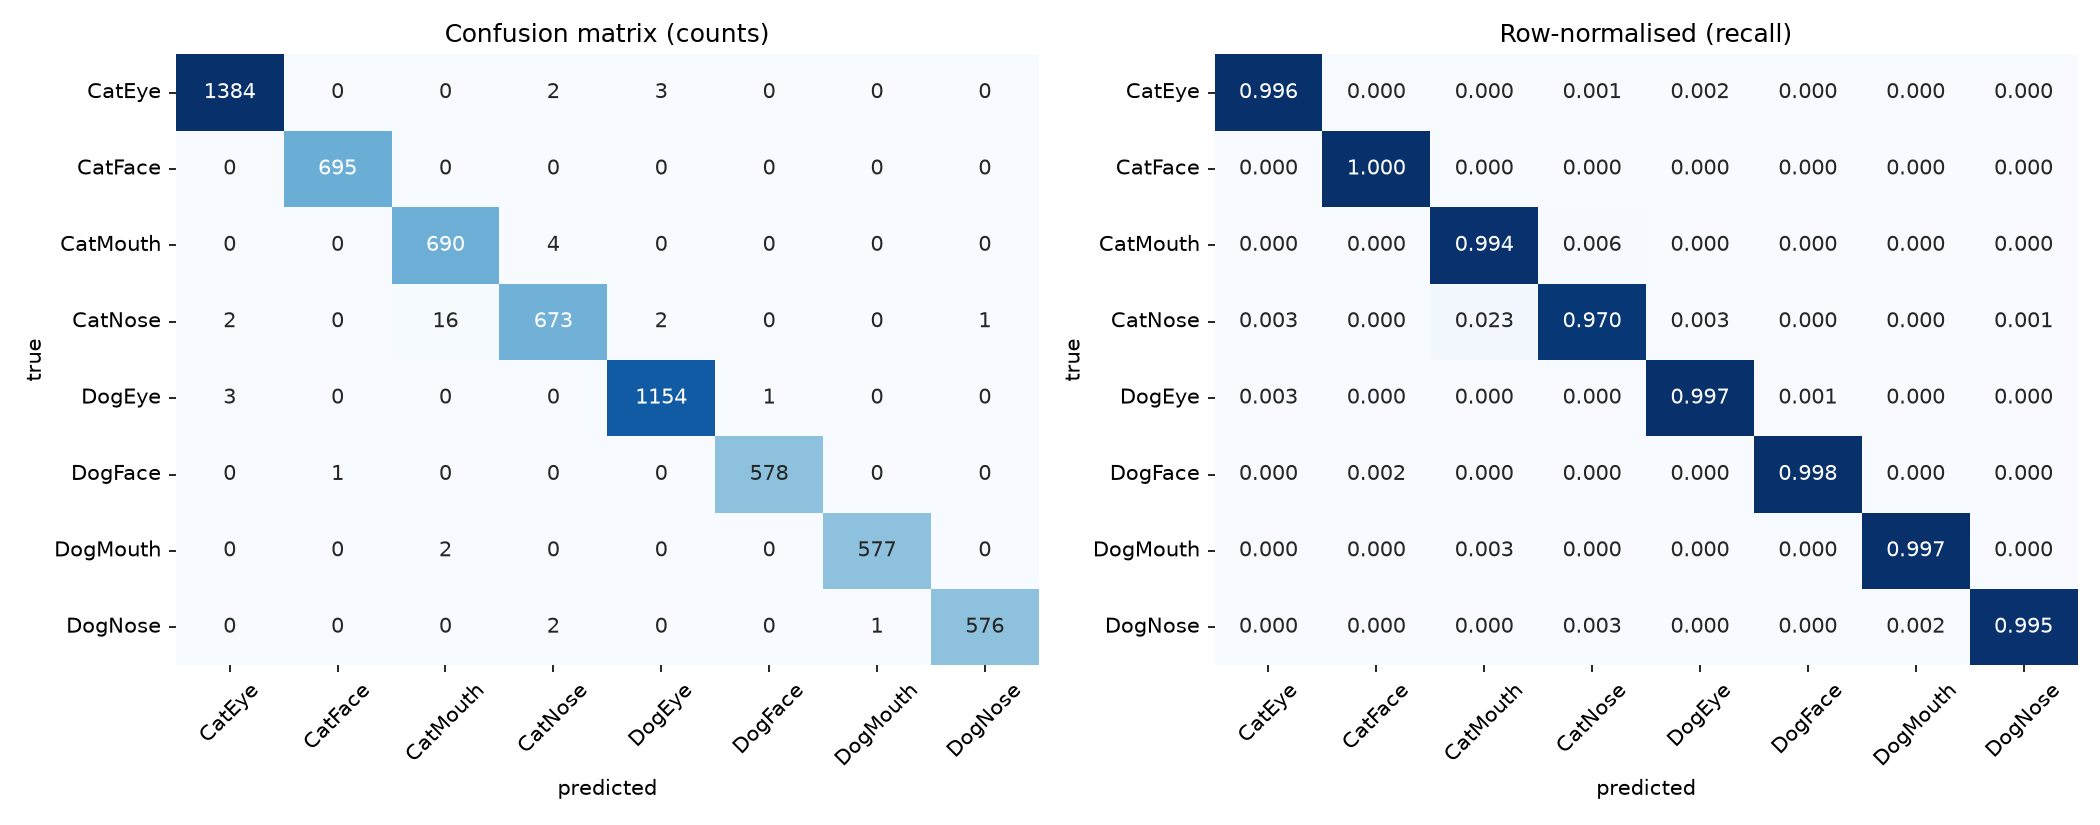

(29443, 2)
   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4   DogFace
4         5  CatMouth
class
CatEye      6342
DogEye      5513
CatMouth    3249
CatFace     3122
CatNose     2885
DogMouth    2816
DogFace     2805
DogNose     2711
Name: count, dtype: int64


In [8]:
for tag in ['resnet18_64','smallcnn_64']:
    f = OUT_DIR/f'val_metrics_{tag}.json'
    if f.exists(): print(tag, json.load(open(f)))
print(pd.read_csv(OUT_DIR/'classification_report_resnet18_64.csv', index_col=0))
display(Image(str(OUT_DIR/'confusion_resnet18_64.png')))
sub = pd.read_csv(OUT_DIR/'submission_resnet18_64.csv'); print(sub.shape); print(sub.head()); print(sub['class'].value_counts())

**Kaggle leaderboard result:** `<ADD SCORE>` (private/public) - screenshot saved as `evidence/leaderboard.png`.
Compare with the validation accuracy above.

## 6. Error analysis (Task 6)

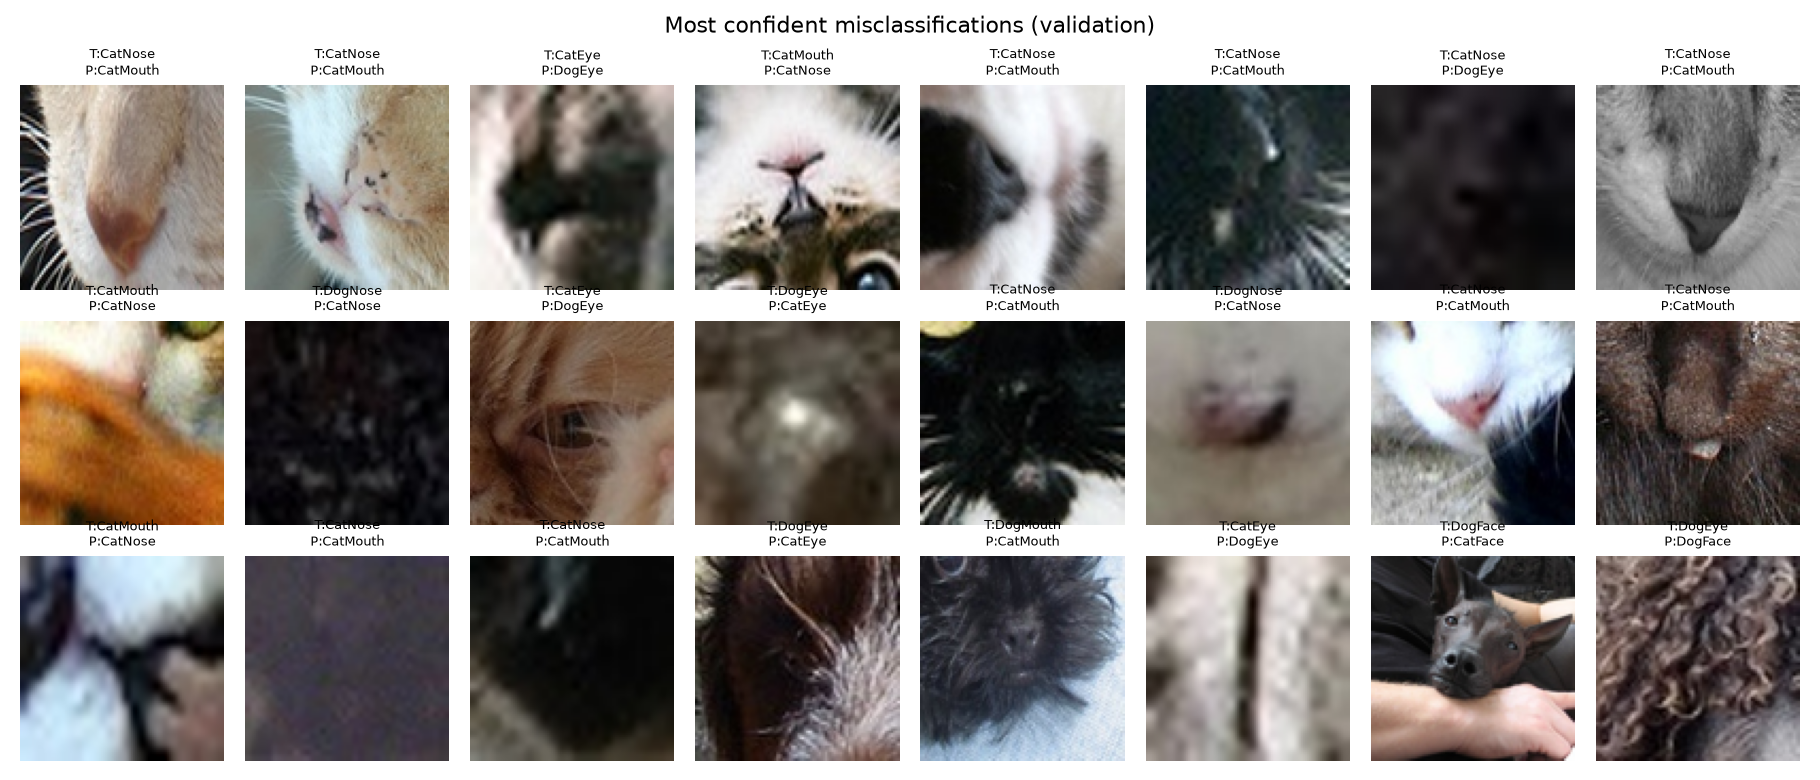

In [9]:
display(Image(str(OUT_DIR/'errors_resnet18_64.png')))

Most errors are CatNose predicted as CatMouth (and vice versa): the Cat 'mouth' crop already contains the nose, so the
labels overlap. Eyes are almost never confused with anything else. See the report for discussion and improvement ideas.